In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [ ]:
x = 6 * np.random.rand(400,1) - 3
y = 0.8 * x**2 + 0.9*x + np.random.randn(400,1)

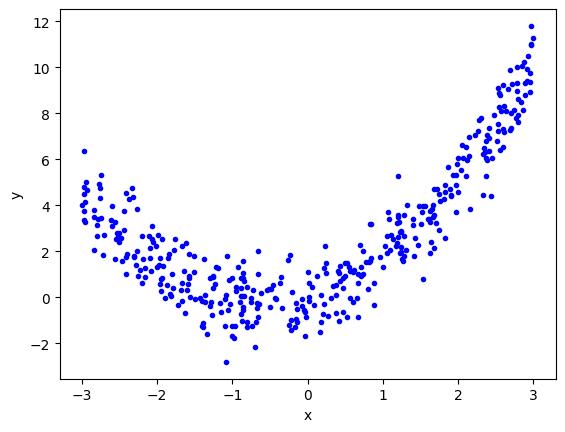

In [ ]:
plt.plot(x,y,'b.')
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [ ]:
x_train , x_test , y_train , y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
  )

using simple linear regression

In [ ]:
lr = LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred = lr.predict(x_test)
r2_score(y_test,y_pred)

0.28936066425728624

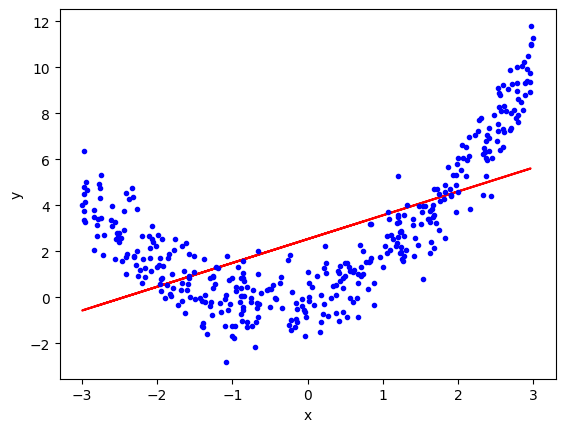

In [ ]:
plt.plot(x_train,lr.predict(x_train),color='r')
plt.plot(x,y,"b.")
plt.xlabel('x')
plt.ylabel('y')
plt.show()

applying polynomial features

In [ ]:
poly = PolynomialFeatures(degree=2,include_bias=True)  # if you do , include_bias = False , you wont get element with zero power i.e B0
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.fit_transform(x_test)

print(x_train[0])
print(x_train_poly[0])

[0.73810213]
[1.         0.73810213 0.54479475]


In [ ]:
lr = LinearRegression()
lr.fit(x_train_poly,y_train)

LinearRegression()

In [ ]:
y_pred = lr.predict(x_test_poly)
r2_score(y_test,y_pred)

0.9059800238336335

In [ ]:
print(lr.coef_)
print(lr.intercept_)

[[0.         0.91884451 0.80384925]]
[0.00745063]


almost equal to the original equation

In [ ]:
x_new = np.sort(x, axis=0)
x_new_poly = poly.transform(x_new)
y_new = lr.predict(x_new_poly)

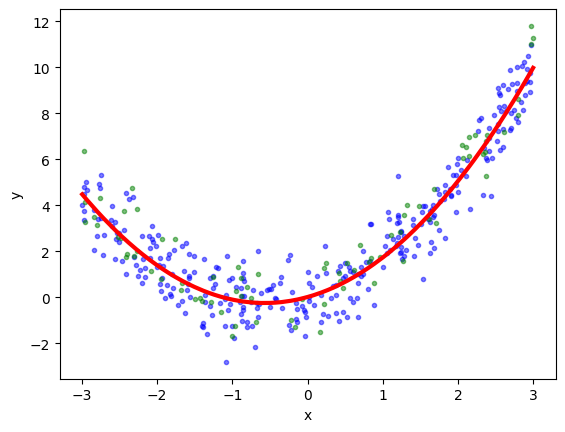

In [ ]:
plt.plot(x_train,y_train,"b.",label="training points",alpha=0.5)
plt.plot(x_test,y_test,"g.",label="testing points",alpha=0.5)
plt.plot(x_new,y_new,"r-",label='predictions',alpha=1,linewidth=3)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [ ]:
def polynomial_regression(degree):
  x_new = np.sort(x,axis=0)
  x_new_poly = poly.transform(x_new)

  polybig_features = PolynomialFeatures(degree = degree , include_bias = False)
  std_scaler = StandardScaler()
  lin_reg = LinearRegression()

  polynomial_regression = Pipeline([
      ("poly_features",polybig_features),
      ("std_scaler",std_scaler),
      ("lin_reg",lin_reg),
  ])

  polynomial_regression.fit(x,y)
  y_newbig = polynomial_regression.predict(x_new)
  plt.plot(x_new,y_newbig,'r',label = 'degree' + str(degree) , linewidth=3,alpha=1)
  plt.plot(x_train,y_train,'b.',linewidth=3,alpha=0.5)
  plt.plot(x_test,y_test,'g.',linewidth=3,alpha=0.5)
  plt.legend(loc='upper left')
  plt.xlabel('x')
  plt.ylabel('y')
  plt.show()

it starts to overfit as we increase the degree

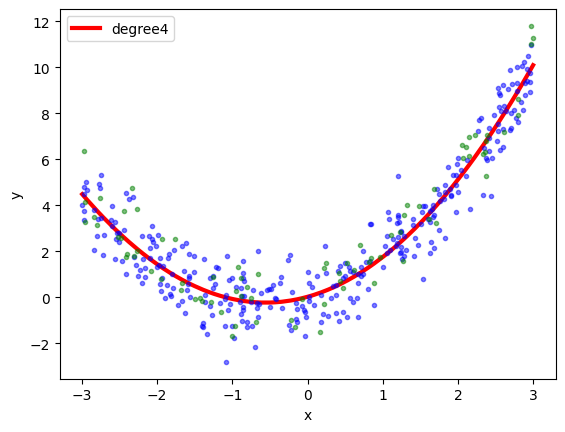

In [ ]:
polynomial_regression(4)

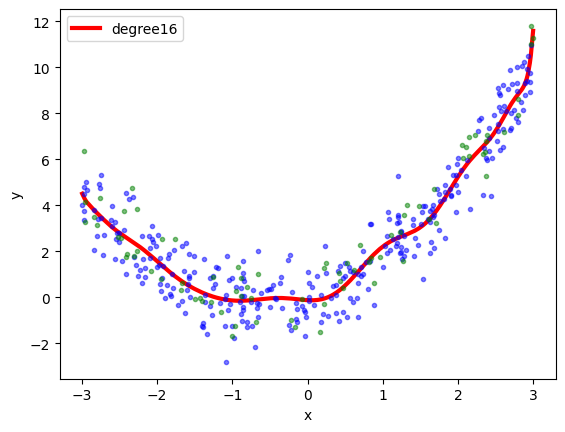

In [ ]:
polynomial_regression(16)

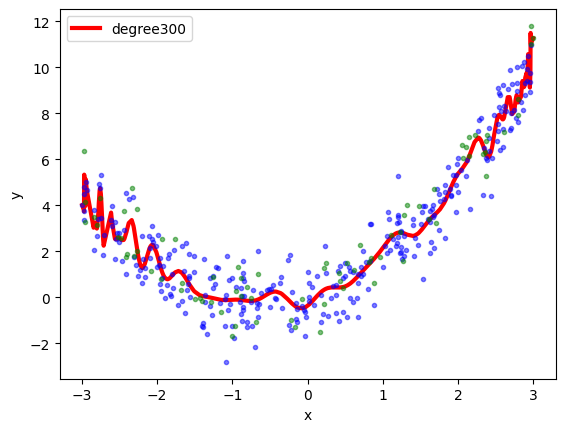

In [ ]:
polynomial_regression(300)